### Analysis: Pre vs Post Meal Probe Choice 

* This section analyzes probe choices made before and after the meal, excluding two participants who performed at or near chance level on the odor prediction task.
* We focus on choice proportions for specific cue pairs of interest, comparing them across the pre- and post-meal phases.
* In particular, we examine choices among the preconditioned cues (A1, A2, C) and the conditioned cues (B1, B2, D). Notably, B2 was associated with the devalued odor.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
import seaborn as sns
from scipy.stats import ttest_rel, wilcoxon
from scipy.stats import pearsonr

In [2]:
# load common plot configurations
from plot_config import session_colors

In [3]:
# Base directory
base_path = Path('/Users/liuq13/project-SPCD/beh_processed_subs/') # converts the string to a pathlib.Path object

In [4]:
# two subjects excluded based on odor prediction task
chance_subjects = ['sub-19', 'sub-33']

In [5]:
# Collect pre/post data
pre_records = []
post_records = []

# Loop through subjects
for subj_folder in sorted(base_path.glob('sub-*')):
    subj = subj_folder.name

    if subj in chance_subjects:
        continue  # skip subjects performing at chance level

    # --- Pre-meal ---
    pre_path = subj_folder / 'pre_meal_dat.csv'
    if pre_path.exists():
        df_pre = pd.read_csv(pre_path)
        
        # drop rows missing key fields
        df_pre = df_pre.dropna(subset=['choice_class', 'acc', 'rt']) # any of them

        # aggregate accuracy & RT by choice_class
        pre = (
            df_pre
            .groupby('choice_class')
            .agg(
                acc=('acc', 'mean'),
                rt=('rt', 'mean')
            )
            .reset_index()
        )
        
        pre['subject'] = subj
        pre['phase'] = 'pre'
        pre_records.append(pre)

    # --- Post-meal ---
    post_path = subj_folder / 'post_meal_dat.csv'
    if post_path.exists():
        df_post = pd.read_csv(post_path)

        # drop rows missing key fields
        df_post = df_post.dropna(subset=['choice_class', 'acc', 'rt'])

        # aggregate accuracy & RT by choice_class
        post = (
            df_post
            .groupby('choice_class')
            .agg(
                acc=('acc', 'mean'),
                rt=('rt', 'mean')
            )
            .reset_index()
        )

        post['subject'] = subj
        post['phase'] = 'post'
        post_records.append(post)

# Combine all
df_all = pd.concat(pre_records + post_records, ignore_index=True)
df_all

,choice_class,acc,rt,subject,phase
0,A1>A2,0.083333,0.698633,sub-01,pre
1,A1>A3,0.083333,0.508827,sub-01,pre
2,A2>A3,0.083333,0.710682,sub-01,pre
3,B1>B2,0.272727,0.588570,sub-01,pre
4,B1>B3,0.000000,0.518104,sub-01,pre
...,...,...,...,...,...
379,A1>A3,0.000000,0.613342,sub-41,post
380,A2>A3,0.090909,0.629265,sub-41,post
381,B1>B2,0.900000,0.815376,sub-41,post
382,B1>B3,0.090909,0.656021,sub-41,post


### rename A3 to C and B3 to D to make this more intuitive and consistent with manuscript writing

In [6]:
df_all['choice_class'] = (
    df_all['choice_class']
    .str.replace('A3', 'C', regex=False)
    .str.replace('B3', 'D', regex=False)
)

In [7]:
df_all.head(10)

,choice_class,acc,rt,subject,phase
0,A1>A2,0.083333,0.698633,sub-01,pre
1,A1>C,0.083333,0.508827,sub-01,pre
2,A2>C,0.083333,0.710682,sub-01,pre
3,B1>B2,0.272727,0.588570,sub-01,pre
4,B1>D,0.000000,0.518104,sub-01,pre
5,B2>D,0.000000,0.590168,sub-01,pre
6,A1>A2,0.000000,0.481733,sub-02,pre
7,A1>C,0.083333,0.523331,sub-02,pre
8,A2>C,0.833333,0.693512,sub-02,pre
9,B1>B2,0.000000,0.544588,sub-02,pre


### If the right side is A2 or B2, then reverse it to prepare for the plot to make it easier to understand

In [8]:
import re

def reverse_choice(row):
    cc = row['choice_class']

    # Match patterns like "A1>A2" or "B1>B2"
    m = re.match(r'([AB]\d)>([AB]\d)', cc)
    if m:
        left, right = m.groups()
        # If the right side is A2 or B2, then reverse it
        if right in ['A2', 'B2']:
            new_cc = f"{right}>{left}"
            new_acc = 1 - row['acc']
            return pd.Series([new_cc, new_acc])
    
    # Otherwise return as-is
    return pd.Series([cc, row['acc']])

df_all[['choice_class', 'acc']] = df_all.apply(reverse_choice, axis=1)
df_all.head(6)

,choice_class,acc,rt,subject,phase
0,A2>A1,0.916667,0.698633,sub-01,pre
1,A1>C,0.083333,0.508827,sub-01,pre
2,A2>C,0.083333,0.710682,sub-01,pre
3,B2>B1,0.727273,0.588570,sub-01,pre
4,B1>D,0.000000,0.518104,sub-01,pre
5,B2>D,0.000000,0.590168,sub-01,pre


### save the pivoted wide format data in drive

In [9]:
# Pivot to wide format (pre, post)
pivoted = df_all.pivot_table(index=['subject', 'choice_class'], columns='phase', values='acc').reset_index()
pivoted['change'] = pivoted['post'] - pivoted['pre']

# save pivoted df to drive
output_file = base_path / 'probe_choice_behavior_all.csv'

# Save the DataFrame
pivoted.to_csv(output_file, index=False)
pivoted.head(6)

phase,subject,choice_class,post,pre,change
0,sub-01,A1>C,0.166667,0.083333,0.083333
1,sub-01,A2>A1,0.000000,0.916667,-0.916667
2,sub-01,A2>C,0.000000,0.083333,-0.083333
3,sub-01,B1>D,0.000000,0.000000,0.000000
4,sub-01,B2>B1,0.000000,0.727273,-0.727273
5,sub-01,B2>D,0.000000,0.000000,0.000000


### perform stat test per choice_class

In [10]:
# Perform statistical test per choice_class
print("Statistical Comparison (Post vs Pre):\n")
for cls in pivoted['choice_class'].unique():
    subset = pivoted[pivoted['choice_class'] == cls].dropna(subset=['pre', 'post'])

    if subset.shape[0] < 3:
        print(f"{cls}: not enough data (n={subset.shape[0]})")
        continue

    try:
        stat, p = wilcoxon(subset['post'], subset['pre'])
        print(f"{cls}: Wilcoxon signed-rank test: p = {p:.4f}")
    except ValueError as e:
        print(f"{cls}: Error - {str(e)}")

Statistical Comparison (Post vs Pre):

A1>C: Wilcoxon signed-rank test: p = 0.2296
A2>A1: Wilcoxon signed-rank test: p = 0.0021
A2>C: Wilcoxon signed-rank test: p = 0.0043
B1>D: Wilcoxon signed-rank test: p = 0.5085
B2>B1: Wilcoxon signed-rank test: p = 0.0015
B2>D: Wilcoxon signed-rank test: p = 0.0183


### Statistical Comparison: Post‐ vs Pre‐Meal Choices  

**Wilcoxon signed‐rank tests** were performed for each choice class to compare choice proportions before and after the meal. 
**Key takeaways**:
- Significant shifts were observed for **A2>A1**, **A2>C**, **B2>B1**, and **B2>D**.
- **A1>C** and **B1>D** did not show significant changes.

This demonstrates sensory-specific devaluation and model-based inference: participants not only reduced choices for the devalued cue (B2) but also for its associated preconditioned cue (A2). The significant changes in choice behavior before and after the meal support the hypothesis that participants used their internal model of cue–cue and cue-outcome associations to update preferences.

### Plot probe choices pre and post meal

/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_14168/855677542.py:13: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


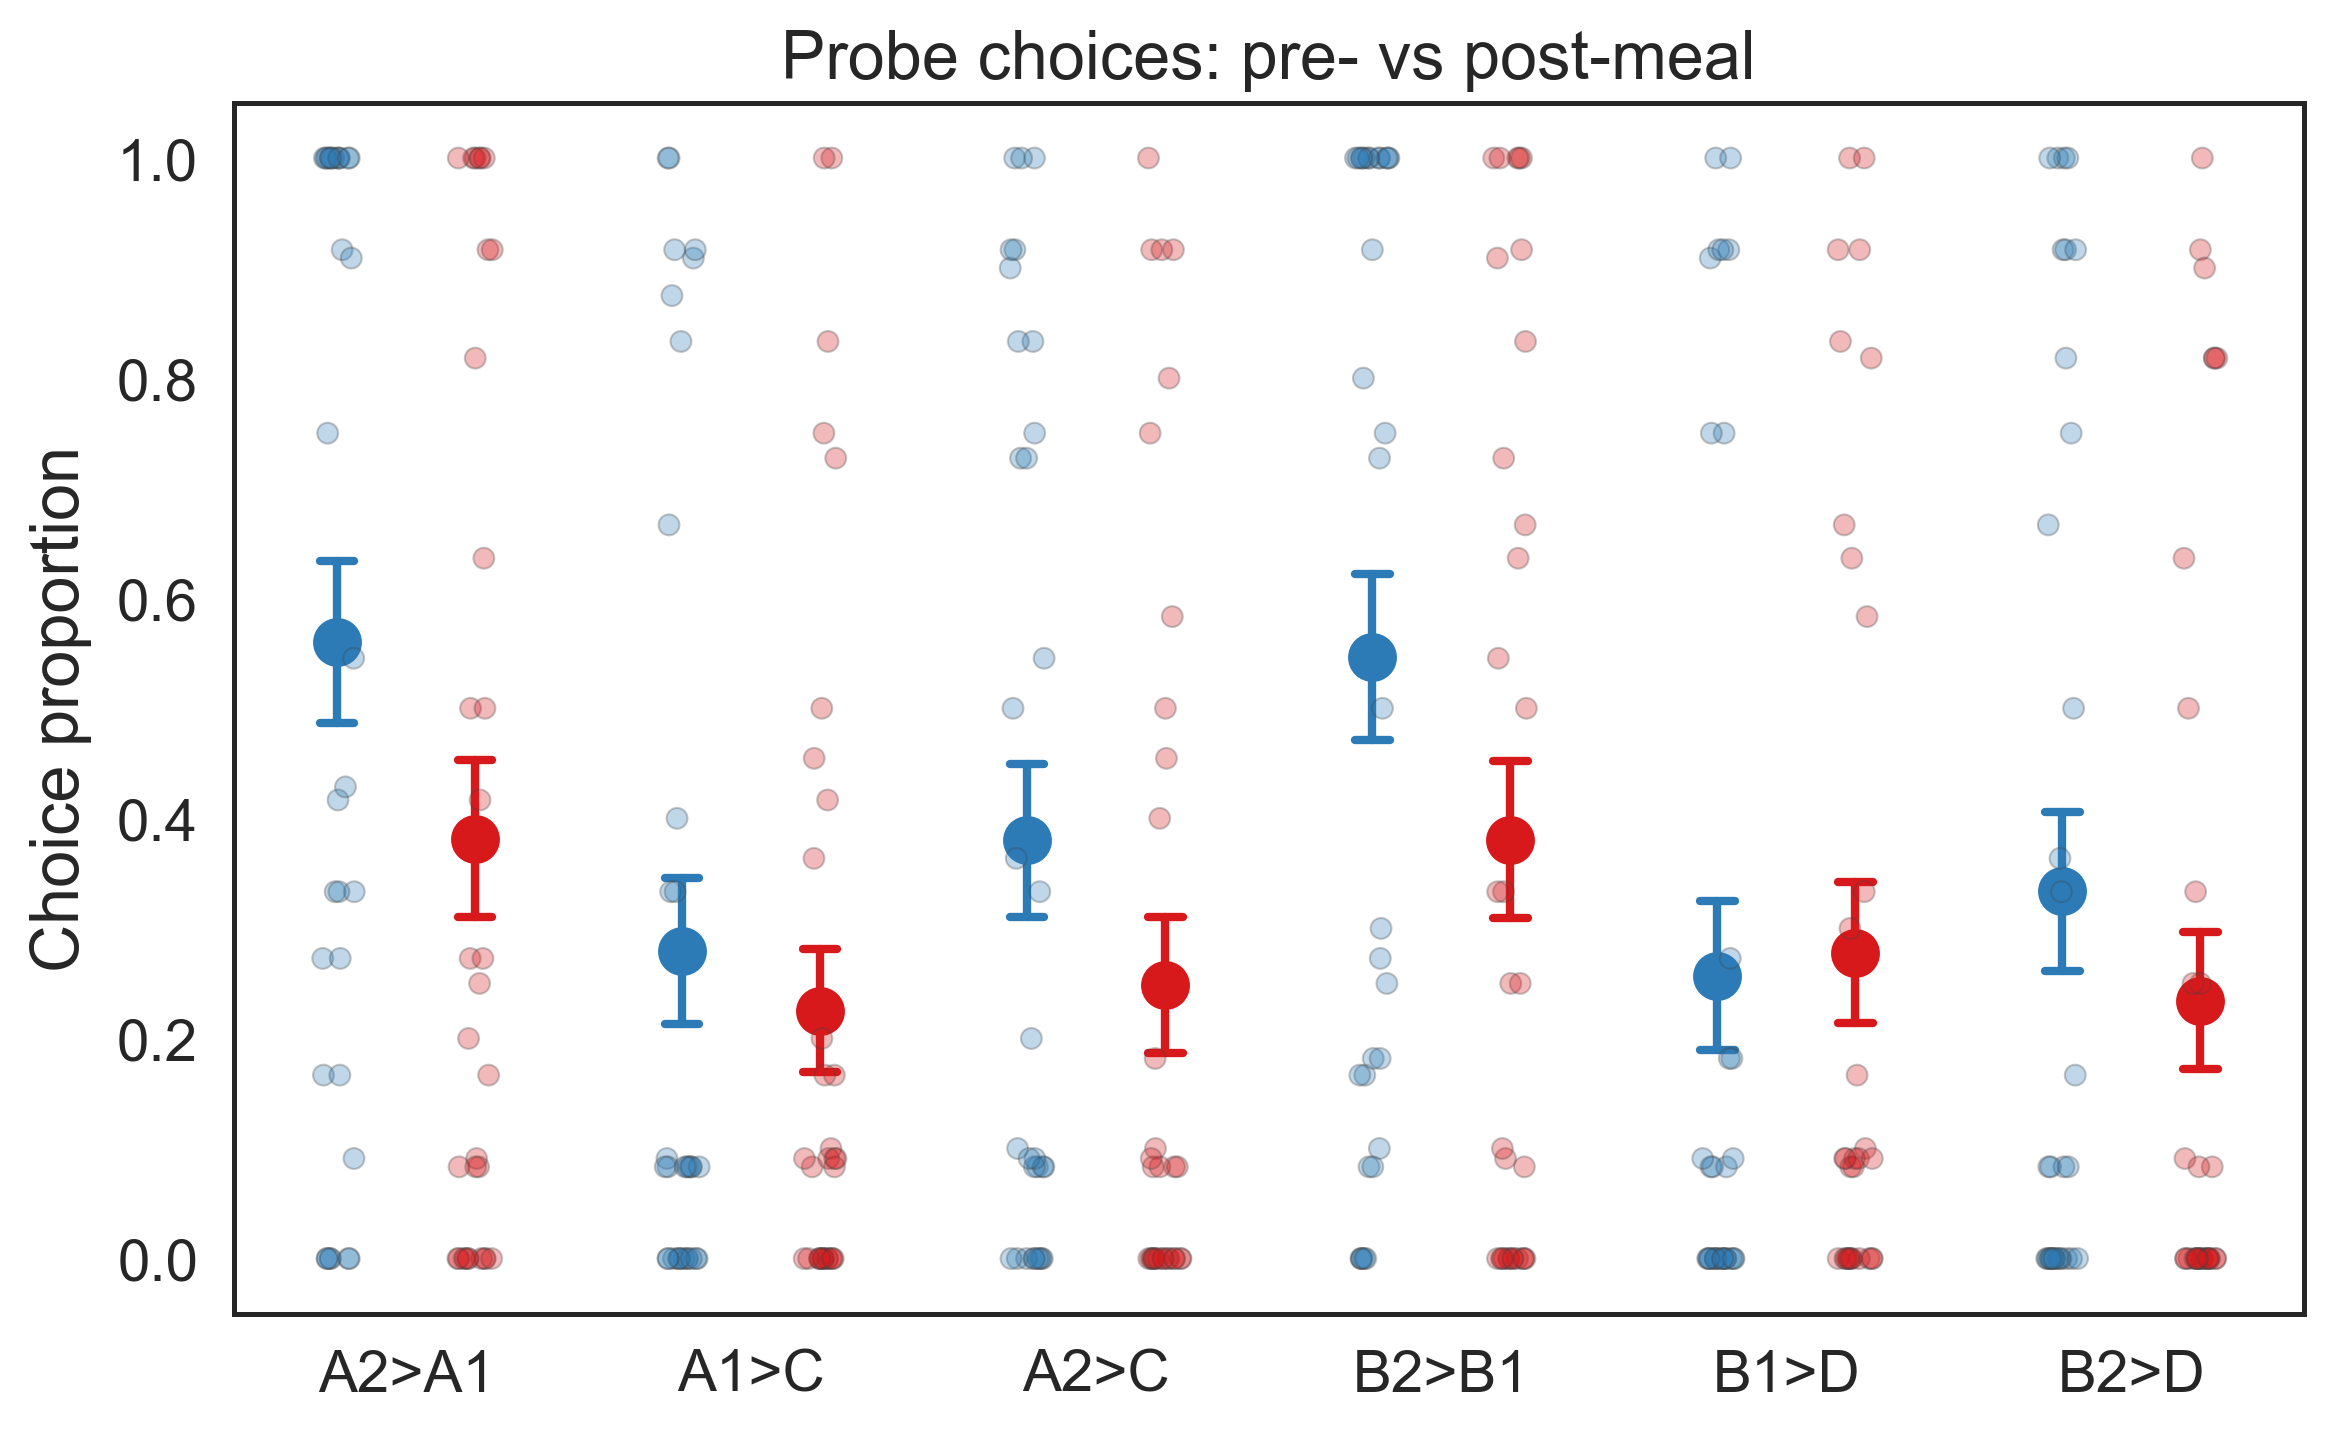

In [11]:
# Plot
plt.figure(figsize=(8, 5))

# Mean ± SE bar with pointplot
sns.pointplot(
    data=df_all, x='choice_class', y='acc', hue='phase',
    errorbar='se', dodge=0.4, palette=session_colors,
    markers='o', linestyles='none', err_kws={'linewidth': 2}, 
    capsize=0.1
)

# Stripplot overlaid (individual data points)
sns.stripplot(
    data=df_all, x='choice_class', y='acc', hue='phase',
    dodge=True, jitter=True, alpha=0.3, linewidth=0.5, edgecolor='gray',
    palette=session_colors
)

# Final touches
plt.title('Probe choices: pre- vs post-meal')
plt.xlabel('')
plt.ylabel('Choice proportion')
plt.ylim(-0.05, 1.05)

# Remove legend
plt.gca().get_legend().remove()
#plt.legend(title='Phase', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('../plots/probe.pdf', format='pdf', bbox_inches='tight')
plt.show()

### To plot for preconditioned cues and conditioned cues in separate panels, and focus on the change

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- define the two parts ----------
part1_labels = ["B2>B1", "B2>D", "B1>D"]      # B1, B2, D pairs
part2_labels = ["A2>A1", "A2>C", "A1>C"]      # A1, A2, C pairs

# precompute full group stats (mean + SEM)
group_stats = (
    pivoted.groupby("choice_class")["change"]
      .agg(mean="mean",
           sem=lambda x: x.std(ddof=1) / np.sqrt(len(x)))
)

group_stats

,mean,sem
choice_class,,
A1>C,-0.054143,0.049341
A2>A1,-0.179018,0.056072
A2>C,-0.131818,0.043691
B1>D,0.020786,0.059988
B2>B1,-0.165767,0.056980
B2>D,-0.099479,0.040088


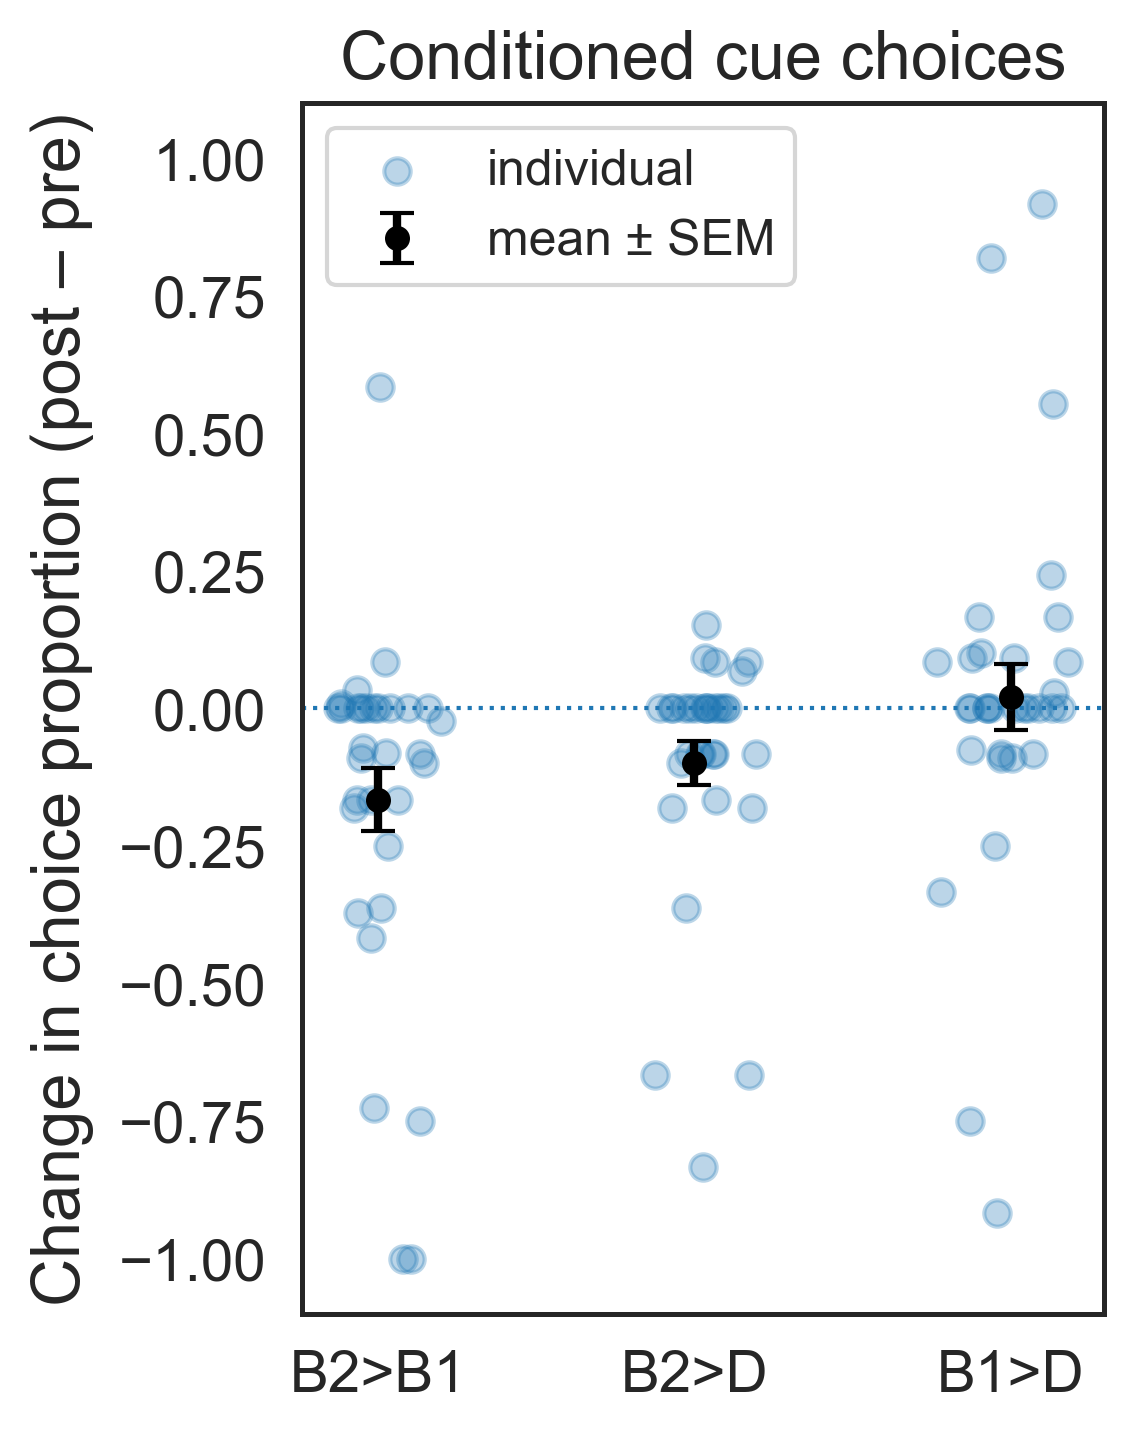

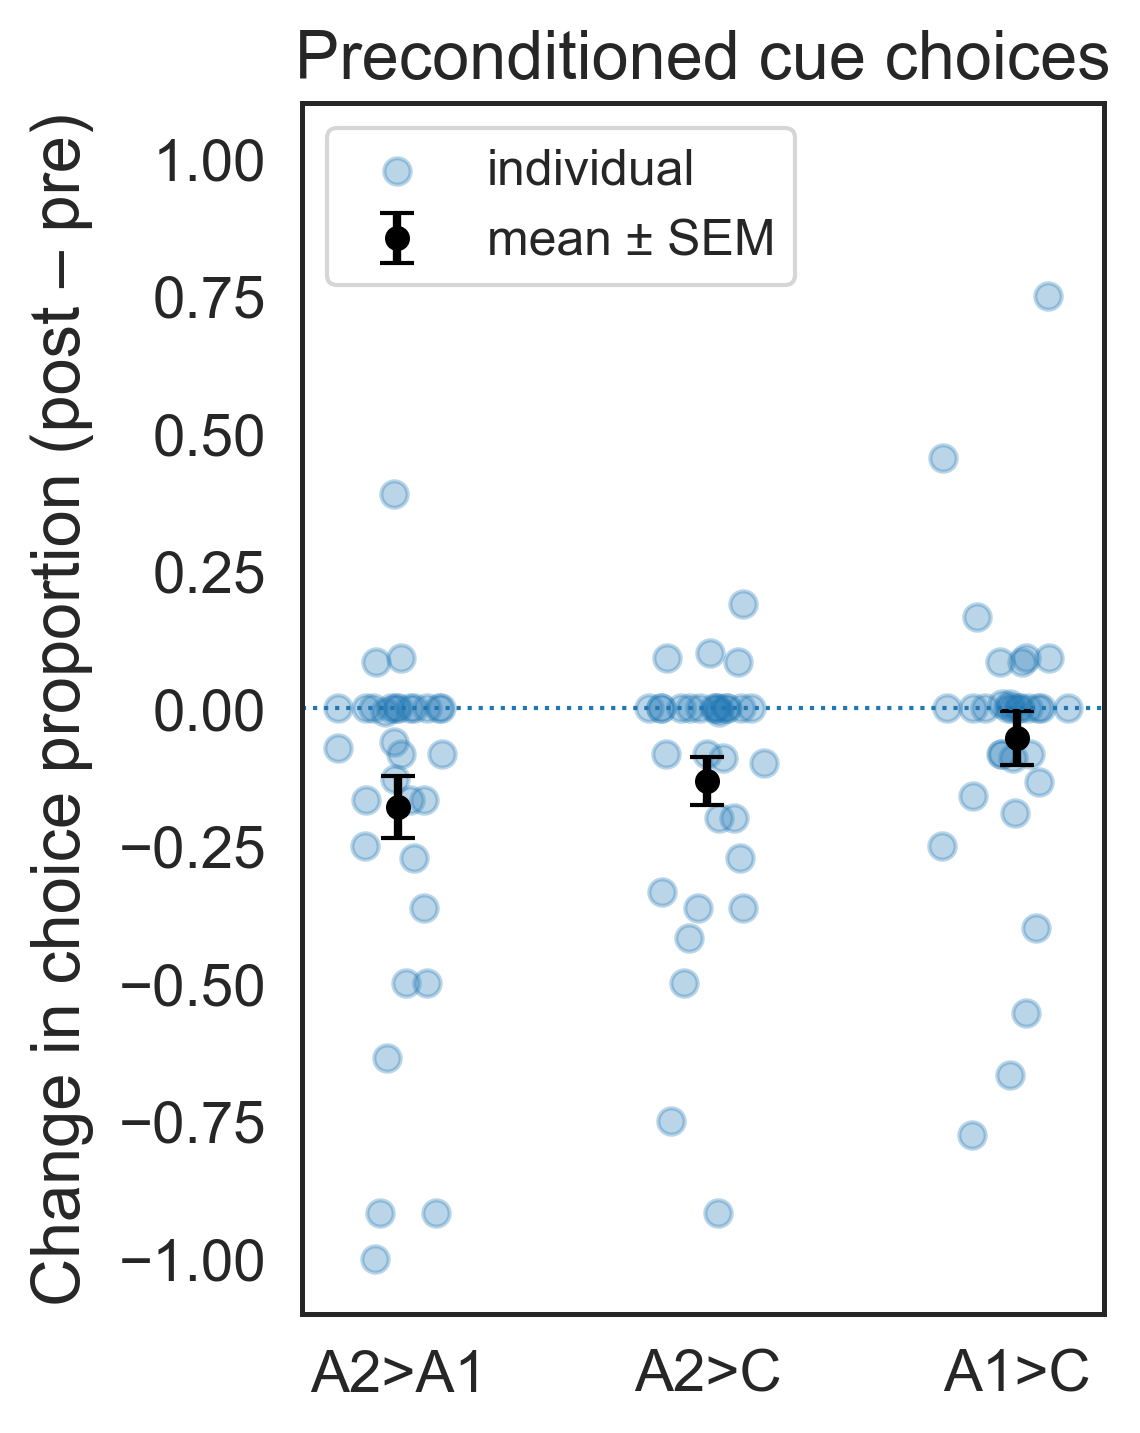

In [13]:
rng = np.random.default_rng(0)

# ---------- helper to make ONE plot in your style ----------
def plot_part(label_list, title, outfile):
    # subset data & stats in desired order
    df_part = pivoted[pivoted["choice_class"].isin(label_list)].copy()
    gs_part = group_stats.loc[label_list].reset_index()

    # numeric x-positions
    x_vals = np.arange(len(label_list))
    label_to_x = {lab: i for i, lab in enumerate(label_list)}
    df_part["x_pos"] = df_part["choice_class"].map(label_to_x).astype(float)

    # --- plotting ---
    fig, ax = plt.subplots(figsize=(4, 5))

    # jittered individual dots
    x_jitter = rng.normal(0, 0.1, size=len(df_part))
    ax.scatter(
        df_part["x_pos"] + x_jitter,
        df_part["change"],
        alpha=0.3,
        s=40,
        label="individual"
    )

    # mean ± SEM
    ax.errorbar(
        x_vals,
        gs_part["mean"],
        yerr=gs_part["sem"],
        fmt='o',
        markersize=5,
        capsize=4,
        linewidth=2,
        color='black',
        label="mean ± SEM"
    )

    ax.axhline(0, linestyle='dotted', linewidth=1)
    ax.set_xlabel("")
    ax.set_ylabel("Change in choice proportion (post – pre)")
    ax.set_title(title)
    ax.legend(frameon=True, loc='upper left')

    ax.set_xticks(x_vals)
    ax.set_xticklabels(label_list)

    ax.set_ylim(-1.1, 1.1)

    plt.tight_layout()
    plt.savefig(outfile, format='pdf', bbox_inches='tight')
    plt.show()


# ---------- make the two plots ----------
plot_part(part1_labels,
          title="Conditioned cue choices",
          outfile="../plots/probe_diff_B1B2D.pdf")

plot_part(part2_labels,
          title="Preconditioned cue choices",
          outfile="../plots/probe_diff_A1A2C.pdf")

### if only look at pre phase
- to get means and std
- to conduct stat testing

In [14]:
# restrict to pre phase
df_pre = df_all[df_all["phase"] == "pre"]

def m(x):
    return round(x.mean(), 3)

def s(x):
    return round(x.std(), 3)

summary = {
    "A>C_collapsed": {
        "mean": m(df_pre[df_pre["choice_class"].isin(["A1>C", "A2>C"])]["acc"]),
        "sd":   s(df_pre[df_pre["choice_class"].isin(["A1>C", "A2>C"])]["acc"])
    },
    
    "A2>A1": {
        "mean": m(df_pre[df_pre["choice_class"] == "A2>A1"]["acc"]),
        "sd":   s(df_pre[df_pre["choice_class"] == "A2>A1"]["acc"])
    },

    "B>D_collapsed": {
        "mean": m(df_pre[df_pre["choice_class"].isin(["B1>D", "B2>D"])]["acc"]),
        "sd":   s(df_pre[df_pre["choice_class"].isin(["B1>D", "B2>D"])]["acc"])
    },

    "B2>B1": {
        "mean": m(df_pre[df_pre["choice_class"] == "B2>B1"]["acc"]),
        "sd":   s(df_pre[df_pre["choice_class"] == "B2>B1"]["acc"])
    }
}

summary


{'A>C_collapsed': {'mean': np.float64(0.33), 'sd': np.float64(0.384)},
 'A2>A1': {'mean': np.float64(0.561), 'sd': np.float64(0.416)},
 'B>D_collapsed': {'mean': np.float64(0.295), 'sd': np.float64(0.395)},
 'B2>B1': {'mean': np.float64(0.546), 'sd': np.float64(0.427)}}

In [15]:
import numpy as np
from scipy.stats import wilcoxon

# ============================================================
# A-SIDE TESTS
# ============================================================

# ----- 1. Combined A>C (A1>C + A2>C) vs 0.5 -----
ac_values = df_pre[df_pre["choice_class"].isin(["A1>C", "A2>C"])]["acc"]

stat_ac, p_ac = wilcoxon(ac_values - 0.5, alternative="two-sided")
print("A>C combined test vs 0.5:")
print("  W =", stat_ac, ", p =", p_ac)

# ----- 2. A1>A2 vs 0.5 -----
a12_values = df_pre[df_pre["choice_class"] == "A2>A1"]["acc"]

stat_a12, p_a12 = wilcoxon(a12_values - 0.5, alternative="two-sided")
print("\nA2>A1 test vs 0.5:")
print("  W =", stat_a12, ", p =", p_a12)

# ============================================================
# B-SIDE TESTS
# ============================================================

# ----- 3. Combined B>D (B1>D + B2>D) vs 0.5 -----
bd_values = df_pre[df_pre["choice_class"].isin(["B1>D", "B2>D"])]["acc"]

stat_bd, p_bd = wilcoxon(bd_values - 0.5, alternative="two-sided")
print("\nB>D combined test vs 0.5:")
print("  W =", stat_bd, ", p =", p_bd)

# ----- 4. B1>B2 vs 0.5 -----
b12_values = df_pre[df_pre["choice_class"] == "B2>B1"]["acc"]

stat_b12, p_b12 = wilcoxon(b12_values - 0.5, alternative="two-sided")
print("\nB2>B1 test vs 0.5:")
print("  W =", stat_b12, ", p =", p_b12)


A>C combined test vs 0.5:
  W = 468.5 , p = 0.00019220595944421953

A2>A1 test vs 0.5:
  W = 209.5 , p = 0.32171454932540655

B>D combined test vs 0.5:
  W = 421.0 , p = 3.877834567121026e-05

B2>B1 test vs 0.5:
  W = 194.0 , p = 0.2802383488552881
